# 手写数字识别 · 互动教学

选中格子按 `Shift + Enter` 运行（PyCharm 点格子左边绿色三角）。**从上往下一格一格跑**。

每个代码格子里都有逐行中文注释 —— 讲解就在代码里，不用翻别的文档。

## 第 0 关 · 环境自检

In [7]:
import os, sys                      # os=操作系统相关, sys=跟 Python 解释器打交道
from pathlib import Path            # Path 用来处理文件路径（推荐写法）

# 不管从哪个目录启动 notebook，都先找到项目根目录（里面有 data/mnist.pkl.gz）
cur = Path.cwd()                    # 当前工作目录
for p in [cur, *cur.parents]:       # *cur.parents 把"所有上级目录"展开进列表
    if (p / "data" / "mnist.pkl.gz").exists():   # 用 / 拼路径；.exists() 判断存在与否
        ROOT = p
        break
else:                               # for-else：循环没 break 时才走这里
    ROOT = cur
os.chdir(ROOT)                      # 切换到项目根目录
sys.path.insert(0, str(ROOT / "src"))   # 把 src 加进模块搜索路径，才能 import 项目模块

import numpy as np                  # 数值计算库，小名 np
import torch                        # 深度学习框架

# ---- 让 matplotlib 能显示中文 ----
# matplotlib 默认字体 DejaVu Sans 里没有中文字形，不设置的话图上中文会变成方框 □□
import matplotlib
matplotlib.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
matplotlib.rcParams["axes.unicode_minus"] = False   # 顺手修掉负号显示成方块的问题

print("项目根目录 :", ROOT)
print("NumPy      :", np.__version__)
print("PyTorch    :", torch.__version__)
print("CUDA 可用  :", torch.cuda.is_available(),
      torch.cuda.get_device_name(0) if torch.cuda.is_available() else "（CPU 也能跑完本 notebook）")

项目根目录 : c:\Users\ASUS-PC\Desktop\files\code\ml
NumPy      : 2.5.3
PyTorch    : 2.14.0+cu130
CUDA 可用  : True NVIDIA GeForce RTX 5070 Laptop GPU


## 第 1 关 · 数据：一张图在计算机眼里是什么

每张图是 28×28 灰度小图，被拉平成 **784 个数字**（0.0~1.0 表示多黑）。

In [8]:
from mnist_data import load_arrays   # 借用项目里写好的数据模块

arrays = load_arrays()               # 返回字典
(Xtr, ytr), (Xva, yva), (Xte, yte) = arrays["train"], arrays["val"], arrays["test"]

print("训练集 X:", Xtr.shape, " 标签 y:", ytr.shape)   # .shape 查看形状（属性，不加括号）
print("验证集 X:", Xva.shape, " 测试集 X:", Xte.shape)
print()
print("50000 = 图片张数；784 = 28×28 个像素")
print("前 10 张图的正确答案（人工标注）:", ytr[:10])            # 切片取前 10 个
print("每个数字出现的次数        :", np.bincount(ytr, minlength=10))   # 统计每个整数出现几次

训练集 X: (50000, 784)  标签 y: (50000,)
验证集 X: (10000, 784)  测试集 X: (10000, 784)

50000 = 图片张数；784 = 28×28 个像素
前 10 张图的正确答案（人工标注）: [5 0 4 1 9 2 1 3 1 4]
每个数字出现的次数        : [4932 5678 4968 5101 4859 4506 4951 5175 4842 4988]


In [9]:
def show_ascii(x, y, label=""):
    """用字符深浅把 28x28 的图画出来 —— 不用图形库也能"看见"图片"""
    img = x.reshape(28, 28)          # 784 -> 28x28（元素个数不变，只是换看法）
    chars = " .:-=+*#%@"             # 从浅到深的 10 个字符
    print(f"{label}人工标注的答案是: {y}")
    for r in range(28):              # 一行一行打印
        # 下面这行是列表推导（紧凑的 for 循环）：对每一列 c 取一个字符，再 join 成字符串
        print("".join(chars[min(int(img[r, c] * 10), 9)] for c in range(28)))

show_ascii(Xtr[0], ytr[0], "第 1 张图：")

第 1 张图：人工标注的答案是: 5
                            
                            
                            
                            
                            
                =+*.*@@=    
        ..-**@@@@@%*@@#:    
       .@@@@@@@@@@---:.     
        %@@@@@##@@          
        -*=@@%  .*          
           *@-              
           +@#              
            #@:             
            .@%*=           
             -@@@=          
              .#@@+.        
                -@@#        
                 @@@:       
              .+#@@%        
            .+%@@@@#        
           =%@@@@#-         
         :%@@@@#-           
       *%@@@@#-             
    :*%@@@@@+               
    +@@@%++                 
                            
                            
                            


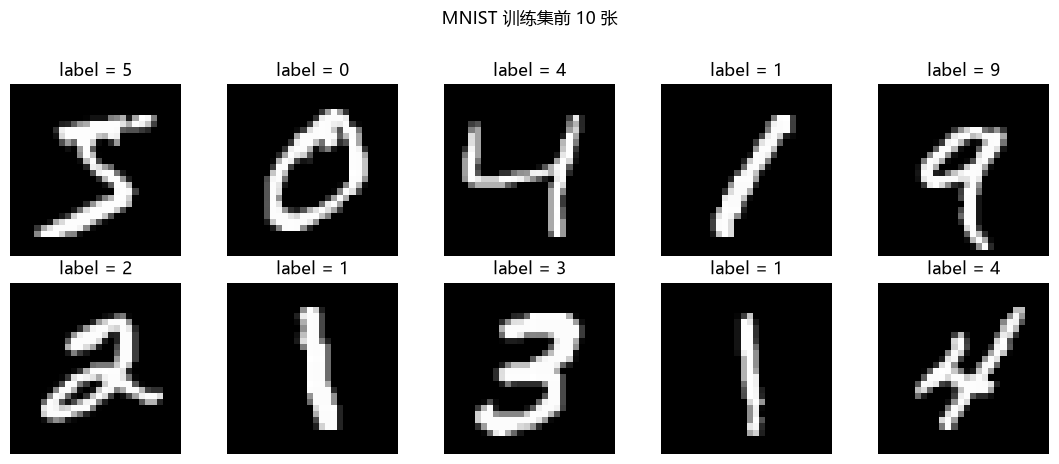

In [10]:
import matplotlib.pyplot as plt     # 画图库

fig, axes = plt.subplots(2, 5, figsize=(11, 4.5))   # 2 行 5 列的子图
for i, ax in enumerate(axes.ravel()):               # enumerate 同时给下标 i 和元素 ax
    ax.imshow(Xtr[i].reshape(28, 28), cmap="gray")  # 784 -> 28x28；gray = 灰度显示
    ax.set_title(f"label = {ytr[i]}")
    ax.axis("off")                                   # 不显示坐标轴
plt.suptitle("MNIST 训练集前 10 张", y=1.02)
plt.tight_layout()
plt.show()

## 第 2 关 · `@` 是什么（矩阵乘法）

神经元做的事：`z = x₁w₁ + x₂w₂ + ... + x₇₈₄w₇₈₄ + b`，用 `@` 一次写完。

In [11]:
x = Xtr[0]                                    # 第 1 张图：784 个数
rng = np.random.default_rng(0)                # 造随机数发生器，种子 0
w = rng.normal(size=784)                      # 假装这是一个神经元的 784 个权重
b = 0.1                                       # 偏置（基础分）

# 写法一：老老实实写循环（慢，但一眼看懂在干什么）
z_loop = sum(x[i] * w[i] for i in range(784)) + b

# 写法二：用 @ （快；所有深度学习代码都这么写）
z_at = x @ w + b

print("手写循环的结果 :", round(float(z_loop), 6))
print("用 @ 的结果    :", round(float(z_at), 6))
print("两者一样吗     :", np.allclose(z_loop, z_at))   # 比较浮点数用 allclose，不用 ==
print()
print("结论：@ 就是「一堆乘法再加起来」的缩写，没有别的魔法。")

手写循环的结果 : -10.97615
用 @ 的结果    : -10.97615
两者一样吗     : True

结论：@ 就是「一堆乘法再加起来」的缩写，没有别的魔法。


In [12]:
A = np.random.randn(5, 784)     # 5 张图
W = np.random.randn(784, 30)    # 784 -> 30 的权重

print("A:", A.shape, "  W:", W.shape)
print("A @ W ->", (A @ W).shape, "  接口对上了：(5,784) @ (784,30) -> (5,30)")
print("W.T   ->", W.T.shape, "   转置 = 行变列、列变行")

try:
    A @ W.T                     # (5,784) @ (30,784)，中间数不同，会报错
except ValueError as e:
    print()
    print("如果忘了写 .T :", e)
    print("这就是新手最常遇到的报错：维度不匹配。")

A: (5, 784)   W: (784, 30)
A @ W -> (5, 30)   接口对上了：(5,784) @ (784,30) -> (5,30)
W.T   -> (30, 784)    转置 = 行变列、列变行

如果忘了写 .T : matmul: Input operand 1 has a mismatch in its core dimension 0, with gufunc signature (n?,k),(k,m?)->(n?,m?) (size 30 is different from 784)
这就是新手最常遇到的报错：维度不匹配。


## 第 3 关 · 激活函数

sigmoid 压到 0~1；ReLU 负数变 0；softmax 把得分变成**加起来等于 1 的概率**。

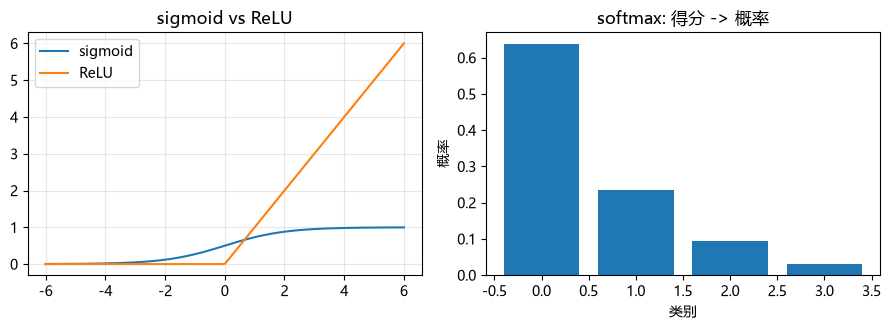

原始得分(logits) : [ 2.   1.   0.1 -1. ]
softmax 后概率   : [0.638 0.235 0.095 0.032]
概率之和         : 1.0  <- 永远等于 1


In [13]:
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))   # clip 防止 exp 溢出

def relu(z):
    return np.maximum(0, z)                                # 逐元素取较大值

def softmax(z):
    z = z - z.max()                 # 减最大值：防指数爆炸，数学上结果不变
    e = np.exp(z)
    return e / e.sum()

zs = np.linspace(-6, 6, 200)        # -6 到 6 之间均匀取 200 个数
plt.figure(figsize=(9, 3.4))
plt.subplot(1, 2, 1)
plt.plot(zs, sigmoid(zs), label="sigmoid")
plt.plot(zs, relu(zs), label="ReLU")
plt.legend(); plt.grid(alpha=0.3); plt.title("sigmoid vs ReLU")

plt.subplot(1, 2, 2)
scores = np.array([2.0, 1.0, 0.1, -1.0])
plt.bar(range(len(scores)), softmax(scores))
plt.title("softmax: 得分 -> 概率"); plt.xlabel("类别"); plt.ylabel("概率")
plt.tight_layout(); plt.show()

print("原始得分(logits) :", scores)
print("softmax 后概率   :", np.round(softmax(scores), 3))
print("概率之和         :", round(float(softmax(scores).sum()), 6), " <- 永远等于 1")

## 第 4 关 · 前向传播：让没训练过的网络猜一次

结构：**784 → 30 → 10**

In [14]:
rng = np.random.default_rng(42)
# Xavier 初始化：标准差取 sqrt(1/上一层大小)，太大太小都学不动
W1 = rng.normal(0, np.sqrt(1 / 784), size=(784, 30)).astype(np.float32)
b1 = np.zeros(30, dtype=np.float32)                          # 偏置初始化为 0
W2 = rng.normal(0, np.sqrt(1 / 30), size=(30, 10)).astype(np.float32)
b2 = np.zeros(10, dtype=np.float32)

x1 = Xtr[0:1]                    # 取 1 张图；写成 [0:1] 而不是 [0]，才能保持 (1,784) 的形状

Z1 = x1 @ W1 + b1                # 第 1 层：加权求和 -> (1,30)
A1 = sigmoid(Z1)                 # 第 1 层：激活
Z2 = A1 @ W2 + b2                # 第 2 层：加权求和 -> (1,10)
A2 = softmax(Z2)                 # 第 2 层：变成概率

print("形状变化:", x1.shape, "->", Z1.shape, "->", Z2.shape)
print("网络给出的 10 个概率:", np.round(A2[0], 3))
print("它猜的是            :", A2.argmax())     # argmax = 最大值在第几个位置
print("正确答案是          :", ytr[0])
print()
print("猜错很正常 —— 权重还是随机数，它什么都没学过。")

形状变化: (1, 784) -> (1, 30) -> (1, 10)
网络给出的 10 个概率: [0.183 0.08  0.117 0.132 0.062 0.044 0.11  0.05  0.108 0.113]
它猜的是            : 0
正确答案是          : 5

猜错很正常 —— 权重还是随机数，它什么都没学过。


## 第 5 关 · 损失函数

交叉熵：`损失 = -log(模型给正确答案的概率)`

In [15]:
print("模型给【正确答案】的概率  ->  损失")
print("-" * 42)
for p in [0.99, 0.9, 0.5, 0.1, 0.01, 0.001]:
    bar = "#" * int(-np.log(p) * 4)      # 字符串 × 数字 = 重复
    print(f"  {p:<6}                {bar:<28} {-np.log(p):6.2f}")
print()
print("越接近 1，损失越接近 0；越自信地猜错，损失爆炸式增长。")

模型给【正确答案】的概率  ->  损失
------------------------------------------
  0.99                                                 0.01
  0.9                                                  0.11
  0.5                   ##                             0.69
  0.1                   #########                      2.30
  0.01                  ##################             4.61
  0.001                 ###########################    6.91

越接近 1，损失越接近 0；越自信地猜错，损失爆炸式增长。


## 第 6 关 · 反向传播（心脏）

算出**每个权重对错误该负多少责任**（梯度），然后按责任大小改它。

In [16]:
Y = np.zeros((1, 10), dtype=np.float32)   # 正确答案写成 one-hot（只有正确那一列是 1）
Y[0, ytr[0]] = 1.0

# ---- 从输出层往回推 ----
dZ2 = (A2 - Y) / 1                 # softmax + 交叉熵求导后特别干净：预测 - 答案
dW2 = A1.T @ dZ2                   # A1.T 是转置；(30,1)@(1,10) -> (30,10)，和 W2 同形状
db2 = dZ2.sum(axis=0)              # axis=0 = 跨样本压扁

dA1 = dZ2 @ W2.T                   # 把"责任"传回上一层，所以用 W2 的转置
dZ1 = dA1 * A1 * (1 - A1)          # * 是逐元素相乘（不是矩阵乘！）；乘 sigmoid 的导数 a(1-a)
dW1 = x1.T @ dZ1                   # (784,1)@(1,30) -> (784,30)，和 W1 同形状
db1 = dZ1.sum(axis=0)

print("每一步的形状（和前向传播一一对应）：")
for name, arr in [("dZ2", dZ2), ("dW2", dW2), ("db2", db2),
                  ("dA1", dA1), ("dZ1", dZ1), ("dW1", dW1), ("db1", db1)]:
    print(f"  {name:4s} {str(arr.shape):12s}")

print()
print("最后一步【梯度下降】：参数 = 参数 - 学习率 × 梯度")
lr = 1.0
print(f"  更新前 W2[0,0]: {W2[0, 0]: .6f}")
W2 -= lr * dW2                     # a -= b 就是 a = a - b
print(f"  更新后 W2[0,0]: {W2[0, 0]: .6f}   （往「让损失变小」的方向走了一小步）")

每一步的形状（和前向传播一一对应）：
  dZ2  (1, 10)     
  dW2  (30, 10)    
  db2  (10,)       
  dA1  (1, 30)     
  dZ1  (1, 30)     
  dW1  (784, 30)   
  db1  (30,)       

最后一步【梯度下降】：参数 = 参数 - 学习率 × 梯度
  更新前 W2[0,0]: -0.058468
  更新后 W2[0,0]: -0.163435   （往「让损失变小」的方向走了一小步）


## 第 7 关 · 真的训练一次

In [17]:
from step1_numpy_nn import Network        # 第 1 步写好的纯 NumPy 网络

net = Network([784, 30, 10], seed=42)
Ytr = np.eye(10, dtype=np.float32)[ytr]   # np.eye(10) 是单位矩阵，用它做 one-hot

epochs, batch, lr = 5, 10, 1.0
rng = np.random.default_rng(0)

for epoch in range(1, epochs + 1):
    perm = rng.permutation(len(Xtr))      # 每轮打乱顺序
    total, nb = 0.0, 0
    for s in range(0, len(Xtr), batch):   # range(0, n, 10) = 0,10,20,... 每次跳 batch 格
        idx = perm[s:s + batch]           # 这一批用哪些样本
        total += net.train_step(Xtr[idx], Ytr[idx], lr)   # 前向+损失+反向+更新，一次搞定
        nb += 1
    acc = net.evaluate(Xva, yva)          # 每轮结束在验证集上考一次
    print(f"epoch {epoch}/{epochs}   平均损失 = {total / nb:.4f}   验证集准确率 = {acc * 100:.2f}%")

print()
print("损失在下降、准确率在上升 —— 这就是「学习」。")

epoch 1/5   平均损失 = 0.3069   验证集准确率 = 94.63%
epoch 2/5   平均损失 = 0.1938   验证集准确率 = 95.15%
epoch 3/5   平均损失 = 0.1709   验证集准确率 = 94.87%


c:\Users\ASUS-PC\Desktop\files\code\ml\src\step1_numpy_nn.py:53: RuntimeWarning: overflow encountered in exp
  return 1.0 / (1.0 + np.exp(-z))    # np.exp = e 的次方


epoch 4/5   平均损失 = 0.1534   验证集准确率 = 95.01%
epoch 5/5   平均损失 = 0.1409   验证集准确率 = 95.30%

损失在下降、准确率在上升 —— 这就是「学习」。


In [18]:
pred = net.predict(Xte[:20])
print("模型预测 :", pred)
print("真实答案 :", yte[:20])
print()
print(f"在 10000 张【从没见过】的测试图上: {net.evaluate(Xte, yte) * 100:.2f}% 正确")
print("（2012 年视频/原书的水平约 95%）")

模型预测 : [7 2 1 0 4 1 4 9 6 9 0 6 9 0 1 5 9 7 3 4]
真实答案 : [7 2 1 0 4 1 4 9 5 9 0 6 9 0 1 5 9 7 3 4]

在 10000 张【从没见过】的测试图上: 94.92% 正确
（2012 年视频/原书的水平约 95%）


## 第 8 关 · 用 PyTorch 做同样的事

框架帮你省掉的就是第 6 关那 7 行求导 —— 一句 `loss.backward()`。

In [19]:
from step2_torch_mlp import MLP, run_epoch
from mnist_data import make_loaders

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("使用设备:", device)

loaders, _ = make_loaders(batch_size=64)      # DataLoader = 自动打乱+分批的"发牌员"
model = MLP(hidden=128).to(device)            # .to(device) 把模型参数搬进 GPU
criterion = torch.nn.CrossEntropyLoss()       # 交叉熵（内部自带 softmax）
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

print(f"参数个数: {sum(p.numel() for p in model.parameters()):,}")   # numel 数一数有多少个数
for ep in range(1, 4):
    loss, tr_acc = run_epoch(model, loaders["train"], criterion, optimizer, device, train_mode=True)
    _, va_acc = run_epoch(model, loaders["val"], criterion, optimizer, device, train_mode=False)
    print(f"epoch {ep}   训练准确率 = {tr_acc * 100:.2f}%   验证准确率 = {va_acc * 100:.2f}%")

print()
print("训练分数 > 验证分数 的那个差距，就是【过拟合】的苗头。")

使用设备: cuda
参数个数: 101,770
epoch 1   训练准确率 = 91.59%   验证准确率 = 95.90%
epoch 2   训练准确率 = 96.08%   验证准确率 = 97.00%
epoch 3   训练准确率 = 97.28%   验证准确率 = 97.06%

训练分数 > 验证分数 的那个差距，就是【过拟合】的苗头。


## 第 9 关 · 加载训练好的 CNN（99%+）

这个模型当初在验证集上的成绩: 99.15%


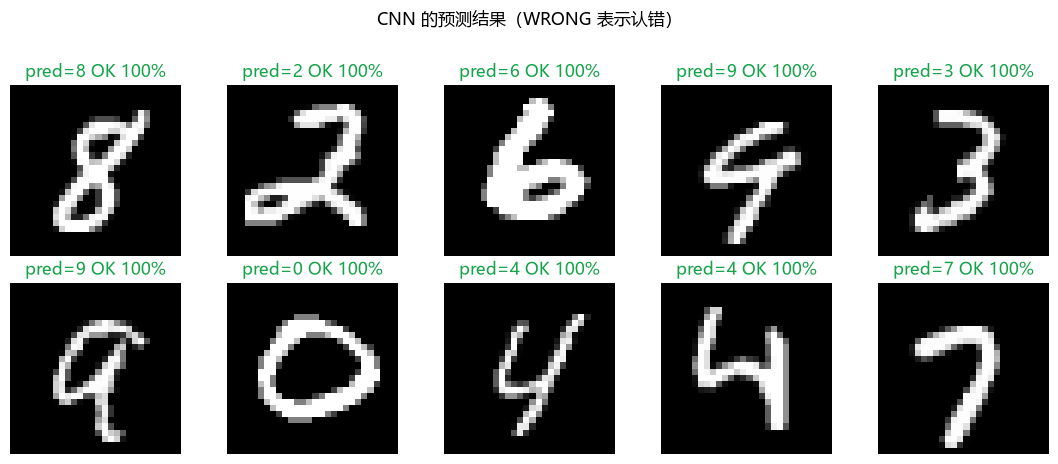

In [20]:
from step3_torch_cnn import SimpleCNN

ckpt = torch.load(ROOT / "models" / "mnist_cnn.pt", map_location="cpu", weights_only=False)
cnn = SimpleCNN()
cnn.load_state_dict(ckpt["state_dict"])   # 把"学到的知识"填回网络
cnn.eval()                                 # 推理模式：关闭 Dropout
mean, std = ckpt["standardize"]            # 训练时用的标准化参数（推理必须一致）

print(f"这个模型当初在验证集上的成绩: {ckpt['val_acc'] * 100:.2f}%")

idx = np.random.default_rng(7).choice(len(Xte), 10, replace=False)   # 随机挑 10 张
with torch.no_grad():                       # 推理不需要梯度
    inp = torch.from_numpy((Xte[idx] - mean) / std)
    probs = torch.softmax(cnn(inp), dim=1)  # 得分 -> 概率
    preds = probs.argmax(1).numpy()

fig, axes = plt.subplots(2, 5, figsize=(11, 4.5))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(Xte[idx[i]].reshape(28, 28), cmap="gray")
    hit = preds[i] == yte[idx[i]]
    ax.set_title(f"pred={preds[i]} {'OK' if hit else 'WRONG'} {probs[i, preds[i]] * 100:.0f}%",
                 color="#16a34a" if hit else "#dc2626")
    ax.axis("off")
plt.suptitle("CNN 的预测结果（WRONG 表示认错）", y=1.02)
plt.tight_layout(); plt.show()

## 你已经掌握的概念

| 你亲手做过的事 | 专业名词 |
|---|---|
| 看 28×28 的数字表格 | 张量 / shape |
| `x @ w + b` | 矩阵乘法 / 前向传播 |
| 把得分变成概率 | softmax |
| `-log(正确答案的概率)` | 交叉熵损失 |
| 往回推责任 | 反向传播 / 链式法则 / 梯度 |
| `参数 -= lr × 梯度` | 梯度下降 / 学习率 |
| 每轮打乱、分批 | epoch / mini-batch |
| 训练分数 > 验证分数 | 过拟合 / 泛化 |
| 加载 `.pt` 做预测 | 推理 / checkpoint / state_dict |

## 下一步

1. 把第 7 关的 `hidden=30` 改成 `8` 或 `128`，`lr` 改成 `0.1` 或 `5.0`，看曲线怎么变
2. 终端运行 `python recognize_draw.py`，用鼠标写数字让模型认
3. 想补 Python 基础：`python src/step0_python_basics.py`